# Tugas Praktikum 4: Association Rule
**Analisis Keranjang Belanja pada Dataset Online Retail (UCI) dengan Apriori dan FP-Growth**

| | |
|---|---|
| Nama | Fauzan Tamma Harish Kunfaza |
| NRP | 5054251035 |

**Tujuan:** menemukan pola/hubungan antar produk yang sering dibeli bersamaan, menggunakan algoritma Apriori (dibandingkan dengan FP-Growth), lalu mengevaluasi aturan dengan metrik *support*, *confidence*, dan *lift*.

**Alur pengerjaan:** (1) impor dataset → (2) eksplorasi & pembersihan → (3) persiapan data transaksi → (4) penerapan algoritma → (5) evaluasi aturan → (6) kesimpulan.

## 0. Import Library

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [3]:
%pip install mlxtend

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Unduh dan Import Dataset

Dataset **Online Retail** diunduh dari UCI Machine Learning Repository (<https://archive.ics.uci.edu/dataset/352/online+retail>) dan dimuat dengan `pd.read_excel`. Letakkan file `Online Retail.xlsx` (atau `Online_Retail.xlsx`) satu folder dengan notebook ini. Proses membaca file Excel sebesar ±23 MB ini memerlukan beberapa menit.

In [4]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
CANDIDATES = ["Online Retail.xlsx", "Online_Retail.xlsx"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Letakkan Online Retail.xlsx di folder yang sama dengan notebook.")

df_raw = pd.read_excel(DATA_PATH)
print("File dimuat:", DATA_PATH)

File dimuat: Online Retail.xlsx


In [6]:
%pip install --upgrade pandas jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
display(df_raw.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.5500,17850.0000,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.3900,17850.0000,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.7500,17850.0000,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.3900,17850.0000,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.3900,17850.0000,United Kingdom


In [8]:
print("Shape (baris, kolom):", df_raw.shape)

Shape (baris, kolom): (541909, 8)


In [9]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


**Deskripsi atribut** (sesuai dokumentasi UCI):

| Kolom | Arti |
|---|---|
| `InvoiceNo` | Nomor invoice (6 digit); diawali huruf **C** berarti transaksi dibatalkan |
| `StockCode` | Kode produk |
| `Description` | Nama produk |
| `Quantity` | Jumlah produk per transaksi |
| `InvoiceDate` | Tanggal dan waktu transaksi |
| `UnitPrice` | Harga satuan (GBP) |
| `CustomerID` | ID pelanggan (banyak yang kosong) |
| `Country` | Negara pelanggan |

Untuk Association Rule, kolom yang relevan hanya **`InvoiceNo`** (identitas transaksi/keranjang) dan **`Description`** (item/produk). Kolom lain dipakai untuk pemeriksaan kualitas data (`Quantity`, `UnitPrice`, `StockCode`) dan eksplorasi (`Country`).

## 2. Eksplorasi dan Pembersihan Data

### 2.1 Eksplorasi awal (sebelum pembersihan)

In [10]:
missing = df_raw.isna().sum().to_frame("jumlah_kosong")
missing["persen"] = missing["jumlah_kosong"] / len(df_raw) * 100
display(missing)

,jumlah_kosong,persen
InvoiceNo,0,0.0000
StockCode,0,0.0000
Description,1454,0.2683
Quantity,0,0.0000
InvoiceDate,0,0.0000
UnitPrice,0,0.0000
CustomerID,135080,24.9267
Country,0,0.0000


In [11]:
df_raw["InvoiceNo"] = df_raw["InvoiceNo"].astype(str)   # kolom campuran (angka & 'C...') -> string

n_cancel_rows = df_raw["InvoiceNo"].str.startswith("C").sum()
n_cancel_inv = df_raw.loc[df_raw["InvoiceNo"].str.startswith("C"), "InvoiceNo"].nunique()
n_qty_nonpos = (df_raw["Quantity"] <= 0).sum()

print(f"Jumlah baris                      : {len(df_raw):,}")
print(f"Jumlah invoice unik               : {df_raw['InvoiceNo'].nunique():,}")
print(f"Baris dengan Description kosong   : {df_raw['Description'].isna().sum():,}")
print(f"Baris invoice dibatalkan ('C...') : {n_cancel_rows:,} ({n_cancel_inv:,} invoice)")
print(f"Baris dengan Quantity <= 0        : {n_qty_nonpos:,}")
print(f"Periode transaksi                 : {df_raw['InvoiceDate'].min()}  s.d.  {df_raw['InvoiceDate'].max()}")

Jumlah baris                      : 541,909
Jumlah invoice unik               : 25,900
Baris dengan Description kosong   : 1,454
Baris invoice dibatalkan ('C...') : 9,288 (3,836 invoice)
Baris dengan Quantity <= 0        : 10,624
Periode transaksi                 : 2010-12-01 08:26:00  s.d.  2011-12-09 12:50:00


In [12]:
display(df_raw[["Quantity", "UnitPrice"]].describe())

,Quantity,UnitPrice
count,541909.0000,541909.0000
mean,9.5522,4.6111
std,218.0812,96.7599
min,-80995.0000,-11062.0600
25%,1.0000,1.2500
50%,3.0000,2.0800
75%,10.0000,4.1300
max,80995.0000,38970.0000


Temuan awal: `Description` kosong pada 1.454 baris, ada invoice pembatalan (awalan `C`), dan `Quantity` ≤ 0 (retur/penyesuaian stok). Baris-baris ini bukan pembelian riil sehingga tidak boleh ikut membentuk keranjang belanja.

### 2.2 Pembersihan data
Langkah **wajib** sesuai ketentuan tugas: (a) hapus `Description` kosong, (b) hapus invoice dibatalkan (`InvoiceNo` berawalan "C"), (c) hapus `Quantity` ≤ 0. Jumlah baris dan invoice dicatat **sebelum** dan **sesudah** setiap langkah.

Setelah itu ditambahkan **langkah tambahan** karena hasil pemeriksaan data menunjukkan masalah yang dapat mengotori aturan: nama produk yang sama tetapi berbeda spasi/huruf (mis. `"WHITE HANGING HEART T-LIGHT HOLDER "`), serta baris non-produk (ongkos kirim, biaya bank, *manual*, voucher) dan baris dengan `UnitPrice` ≤ 0 (penyesuaian stok/barang gratis).

In [13]:
df = df_raw.copy()
log = [("Data awal", len(df), df["InvoiceNo"].nunique())]

# ---- Langkah wajib ----
df = df.dropna(subset=["Description"])
log.append(("Hapus Description kosong", len(df), df["InvoiceNo"].nunique()))

df = df[~df["InvoiceNo"].str.startswith("C")]
log.append(("Hapus invoice dibatalkan (awalan 'C')", len(df), df["InvoiceNo"].nunique()))

df = df[df["Quantity"] > 0]
log.append(("Hapus Quantity <= 0", len(df), df["InvoiceNo"].nunique()))

# ---- Langkah tambahan ----
df = df.copy()
df["Description"] = (df["Description"].astype(str)
                     .str.strip().str.upper().str.replace(r"\s+", " ", regex=True))
df = df[df["Description"] != ""]
log.append(("Normalisasi nama produk (strip/huruf besar) & hapus nama kosong", len(df), df["InvoiceNo"].nunique()))

df["StockCode"] = df["StockCode"].astype(str)
NON_PRODUCT = {"POST", "DOT", "M", "C2", "BANK CHARGES", "B", "S", "AMAZONFEE", "PADS", "CRUK", "D"}
is_non_product = df["StockCode"].isin(NON_PRODUCT) | df["StockCode"].str.startswith("gift_")
df = df[~is_non_product]
log.append(("Hapus baris non-produk (postage, manual, bank charges, voucher, dll.)", len(df), df["InvoiceNo"].nunique()))

df = df[df["UnitPrice"] > 0]
log.append(("Hapus UnitPrice <= 0", len(df), df["InvoiceNo"].nunique()))

df = df.reset_index(drop=True)

In [14]:
log_df = pd.DataFrame(log, columns=["Langkah", "Jumlah baris", "Jumlah invoice"])
log_df["Baris terhapus"] = -log_df["Jumlah baris"].diff().fillna(0).astype(int)
log_df["Invoice terhapus"] = -log_df["Jumlah invoice"].diff().fillna(0).astype(int)
for c in ["Jumlah baris", "Jumlah invoice", "Baris terhapus", "Invoice terhapus"]:
    log_df[c] = log_df[c].map("{:,.0f}".format)
display(log_df)

,Langkah,Jumlah baris,Jumlah invoice,Baris terhapus,Invoice terhapus
0,Data awal,"541,909","25,900",0,0
1,Hapus Description kosong,"540,455","24,446","1,454","1,454"
2,Hapus invoice dibatalkan (awalan 'C'),"531,167","20,610","9,288","3,836"
3,Hapus Quantity <= 0,"530,693","20,136",474,474
4,Normalisasi nama produk (strip/huruf besar) & hapus nama kosong,"530,693","20,136",0,0
5,"Hapus baris non-produk (postage, manual, bank charges, voucher, dll.)","528,336","19,954","2,357",182
6,Hapus UnitPrice <= 0,"527,759","19,773",577,181


In [15]:
sebelum = (len(df_raw), df_raw["InvoiceNo"].nunique())
sesudah = (len(df), df["InvoiceNo"].nunique())
ringkas = pd.DataFrame({"Sebelum pembersihan": sebelum, "Sesudah pembersihan": sesudah},
                       index=["Jumlah baris", "Jumlah invoice"])
ringkas["Berkurang (%)"] = (1 - ringkas["Sesudah pembersihan"] / ringkas["Sebelum pembersihan"]) * 100
ringkas_tampil = ringkas.copy()
for c in ["Sebelum pembersihan", "Sesudah pembersihan"]:
    ringkas_tampil[c] = ringkas_tampil[c].map("{:,.0f}".format)
ringkas_tampil["Berkurang (%)"] = ringkas_tampil["Berkurang (%)"].map("{:.2f}".format)
display(ringkas_tampil)
print("Jumlah produk unik (Description) sesudah pembersihan:", df["Description"].nunique())

,Sebelum pembersihan,Sesudah pembersihan,Berkurang (%)
Jumlah baris,"541,909","527,759",2.61
Jumlah invoice,"25,900","19,773",23.66


Jumlah produk unik (Description) sesudah pembersihan: 3994


### 2.3 Eksplorasi data setelah pembersihan

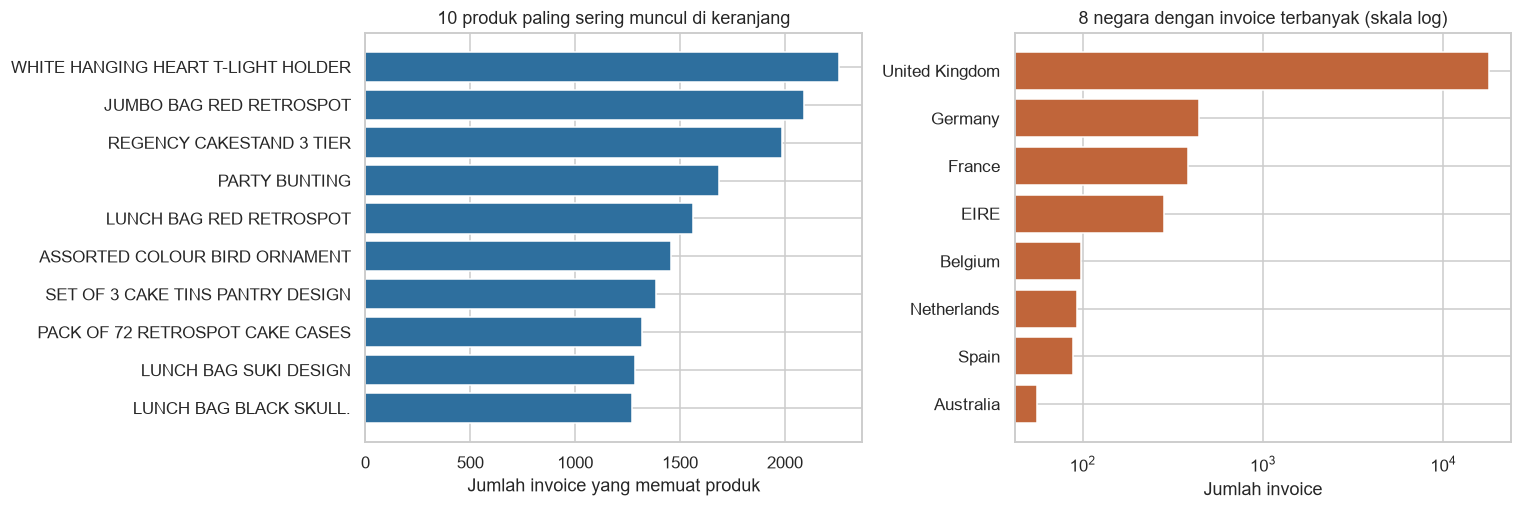

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

top_products = (df.drop_duplicates(["InvoiceNo", "Description"])
                  .groupby("Description")["InvoiceNo"].nunique().nlargest(10).sort_values())
axes[0].barh(top_products.index, top_products.values, color="#2E6F9E")
axes[0].set_title("10 produk paling sering muncul di keranjang")
axes[0].set_xlabel("Jumlah invoice yang memuat produk")

country = df.groupby("Country")["InvoiceNo"].nunique().nlargest(8).sort_values()
axes[1].barh(country.index, country.values, color="#C0653A")
axes[1].set_xscale("log")
axes[1].set_title("8 negara dengan invoice terbanyak (skala log)")
axes[1].set_xlabel("Jumlah invoice")

plt.tight_layout()
plt.show()

,item per invoice
count,19773.0000
mean,26.1451
std,46.9762
min,1.0000
25%,6.0000
50%,15.0000
75%,29.0000
max,1106.0000


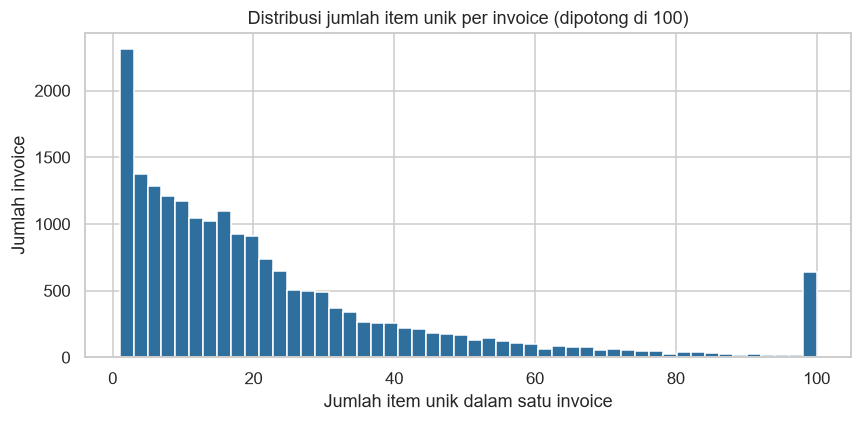

Proporsi invoice dari United Kingdom: 90.5%


In [17]:
items_per_invoice = df.drop_duplicates(["InvoiceNo", "Description"]).groupby("InvoiceNo").size()
display(items_per_invoice.describe().to_frame("item per invoice"))

plt.figure(figsize=(8, 4))
plt.hist(items_per_invoice.clip(upper=100), bins=50, color="#2E6F9E", edgecolor="white")
plt.title("Distribusi jumlah item unik per invoice (dipotong di 100)")
plt.xlabel("Jumlah item unik dalam satu invoice")
plt.ylabel("Jumlah invoice")
plt.tight_layout()
plt.show()

share_uk = df.loc[df["Country"] == "United Kingdom", "InvoiceNo"].nunique() / df["InvoiceNo"].nunique() * 100
print(f"Proporsi invoice dari United Kingdom: {share_uk:.1f}%")

## 3. Persiapan Data untuk Association Rule

Setiap **invoice = satu transaksi (keranjang)** dan setiap **produk (`Description`) = satu item**. Jumlah pembelian (`Quantity`) tidak dipakai karena Association Rule hanya memperhatikan *ada tidaknya* item dalam keranjang. Duplikat (invoice, produk) dihilangkan lebih dahulu agar satu produk hanya dihitung sekali per transaksi.

In [18]:
df_items = df[["InvoiceNo", "Description"]].drop_duplicates()

# Format 1: daftar produk per transaksi
transactions = df_items.groupby("InvoiceNo")["Description"].apply(list)
print("Jumlah transaksi:", len(transactions))
for inv in transactions.index[:3]:
    print(f"\nInvoice {inv} ({len(transactions[inv])} item):")
    print("  ", transactions[inv][:6], "..." if len(transactions[inv]) > 6 else "")

Jumlah transaksi: 19773

Invoice 536365 (7 item):
   ['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN', 'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES'] ...

Invoice 536366 (2 item):
   ['HAND WARMER UNION JACK', 'HAND WARMER RED POLKA DOT'] 

Invoice 536367 (12 item):
   ['ASSORTED COLOUR BIRD ORNAMENT', "POPPY'S PLAYHOUSE BEDROOM", "POPPY'S PLAYHOUSE KITCHEN", 'FELTCRAFT PRINCESS CHARLOTTE DOLL', 'IVORY KNITTED MUG COSY', 'BOX OF 6 ASSORTED COLOUR TEASPOONS'] ...


In [19]:
# Format 2: one-hot / basket (baris = invoice, kolom = produk, nilai = True/False)
inv_codes, inv_index = pd.factorize(df_items["InvoiceNo"])
item_codes, item_index = pd.factorize(df_items["Description"])

mat = np.zeros((len(inv_index), len(item_index)), dtype=bool)
mat[inv_codes, item_codes] = True
basket = pd.DataFrame(mat, index=inv_index, columns=item_index)
basket.index.name = "InvoiceNo"

print("Bentuk basket (transaksi x produk):", basket.shape)
print(f"Kepadatan matriks (proporsi True): {basket.values.mean() * 100:.3f}%  -> data sangat jarang (sparse)")
display(basket.iloc[:5, :6])

Bentuk basket (transaksi x produk): (19773, 3994)
Kepadatan matriks (proporsi True): 0.655%  -> data sangat jarang (sparse)


,WHITE HANGING HEART T-LIGHT HOLDER,WHITE METAL LANTERN,CREAM CUPID HEARTS COAT HANGER,KNITTED UNION FLAG HOT WATER BOTTLE,RED WOOLLY HOTTIE WHITE HEART.,SET 7 BABUSHKA NESTING BOXES
InvoiceNo,,,,,,
536365,True,True,True,True,True,True
536366,False,False,False,False,False,False
536367,False,False,False,False,False,False
536368,False,False,False,False,False,False
536369,False,False,False,False,False,False


## 4. Penerapan Algoritma

Titik awal sesuai ketentuan: **minimum support = 0,01** (produk/kombinasi muncul di ≥ 1% transaksi) dan **minimum confidence = 0,5**. Algoritma utama adalah **Apriori**; hasilnya diverifikasi dengan **FP-Growth** (keduanya harus menghasilkan frequent itemset yang sama).

In [20]:
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.5
N_TRANSAKSI = len(basket)
print(f"Minimum support {MIN_SUPPORT} setara dengan >= {int(np.ceil(MIN_SUPPORT * N_TRANSAKSI))} invoice dari {N_TRANSAKSI:,}")

freq_apriori = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
freq_apriori["panjang"] = freq_apriori["itemsets"].apply(len)
print("Jumlah frequent itemset (Apriori):", len(freq_apriori))
display(freq_apriori["panjang"].value_counts().sort_index().rename_axis("ukuran itemset").to_frame("jumlah"))

Minimum support 0.01 setara dengan >= 198 invoice dari 19,773
Jumlah frequent itemset (Apriori): 1892


,jumlah
ukuran itemset,
1,822
2,819
3,228
4,22
5,1


In [21]:
display(freq_apriori.sort_values("support", ascending=False).head(10))

,support,itemsets,panjang
0,0.1141,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
94,0.1056,frozenset({JUMBO BAG RED RETROSPOT}),1
311,0.1005,frozenset({REGENCY CAKESTAND 3 TIER}),1
603,0.0852,frozenset({PARTY BUNTING}),1
47,0.0791,frozenset({LUNCH BAG RED RETROSPOT}),1
7,0.0736,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
636,0.0700,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
50,0.0668,frozenset({PACK OF 72 RETROSPOT CAKE CASES}),1
186,0.0649,frozenset({LUNCH BAG SUKI DESIGN}),1
188,0.0644,frozenset({LUNCH BAG BLACK SKULL.}),1


In [22]:
freq_fp = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True)
print("Jumlah frequent itemset (FP-Growth):", len(freq_fp))

sup_a = dict(zip(freq_apriori["itemsets"], freq_apriori["support"]))
sup_f = dict(zip(freq_fp["itemsets"], freq_fp["support"]))
sama = (sup_a.keys() == sup_f.keys()) and all(abs(sup_a[k] - sup_f[k]) < 1e-12 for k in sup_a)
print("Apriori dan FP-Growth menghasilkan itemset & support yang identik:", sama)

Jumlah frequent itemset (FP-Growth): 1892
Apriori dan FP-Growth menghasilkan itemset & support yang identik: True


In [23]:
def buat_aturan(freq, metric="confidence", min_threshold=0.5):
    # mlxtend >= 0.24 meminta argumen num_itemsets; versi lama tidak.
    try:
        return association_rules(freq, metric=metric, min_threshold=min_threshold)
    except TypeError:
        return association_rules(freq, num_itemsets=N_TRANSAKSI, metric=metric, min_threshold=min_threshold)

rules = buat_aturan(freq_apriori, "confidence", MIN_CONFIDENCE)
print("Jumlah aturan asosiasi (support >= 0.01, confidence >= 0.5):", len(rules))

Jumlah aturan asosiasi (support >= 0.01, confidence >= 0.5): 879


### Penyesuaian parameter
Ketentuan tugas meminta parameter disesuaikan jika aturan terlalu sedikit atau terlalu banyak. Tabel berikut menguji kombinasi support dan confidence di sekitar titik awal.

In [24]:
hasil = []
for ms in [0.01, 0.015, 0.02, 0.03]:
    f = fpgrowth(basket, min_support=ms, use_colnames=True)
    for mc in [0.5, 0.6, 0.7]:
        r = buat_aturan(f, "confidence", mc) if len(f) > 1 else []
        hasil.append({"min_support": ms, "min_confidence": mc,
                      "frequent itemset": len(f), "jumlah aturan": len(r)})
sens = pd.DataFrame(hasil)
display(sens.pivot(index="min_support", columns="min_confidence", values="jumlah aturan"))

min_confidence,0.5000,0.6000,0.7000
min_support,,,
0.0100,879,540,274
0.0150,207,106,47
0.0200,60,30,13
0.0300,14,9,4


**Keputusan:** parameter awal (**support 0,01; confidence 0,5**) dipertahankan. Dengan jumlah transaksi ±19.800, support 0,01 berarti sebuah pola harus muncul di sekitar 198 invoice; ini cukup untuk menyaring kebetulan statistik namun tetap menangkap pola produk niche (katalog memuat ±4.000 produk, sehingga produk individual memiliki support kecil). Menaikkan support ke 0,02 atau 0,03 membuang hampir seluruh pola antar-produk dan menyisakan aturan yang sebagian besar didominasi produk terlaris. Menaikkan confidence ke 0,7 mengurangi aturan secara drastis dan membuang aturan berguna dengan confidence 0,5–0,7. Jumlah aturan pada titik awal masih dapat dianalisis, sehingga tidak diperlukan perubahan.

## 5. Evaluasi Aturan Asosiasi

**Metrik yang dipakai** (A = antecedent, C = consequent):
- **Support(A→C)** = P(A ∩ C): proporsi transaksi yang memuat A dan C sekaligus.
- **Confidence(A→C)** = P(C | A) = support(A∪C) / support(A): peluang C dibeli bila A sudah ada di keranjang.
- **Lift(A→C)** = confidence / support(C): seberapa kuat hubungan dibanding bila A dan C independen. Lift > 1 berarti A dan C saling melengkapi (dibeli bersama lebih sering dari kebetulan); lift = 1 independen; lift < 1 saling menggantikan.

In [25]:
rules = rules.copy()
rules["antecedents_txt"] = rules["antecedents"].apply(lambda s: " + ".join(sorted(s)))
rules["consequents_txt"] = rules["consequents"].apply(lambda s: " + ".join(sorted(s)))
rules["jumlah_invoice"] = (rules["support"] * N_TRANSAKSI).round().astype(int)
rules["panjang_aturan"] = rules["antecedents"].apply(len) + rules["consequents"].apply(len)

kolom = ["antecedents_txt", "consequents_txt", "support", "confidence", "lift"]
print("Ringkasan statistik metrik seluruh aturan:")
display(rules[["support", "confidence", "lift"]].describe())
print("Aturan dengan lift <= 1:", (rules["lift"] <= 1).sum(), "-> semua aturan memiliki hubungan positif")

Ringkasan statistik metrik seluruh aturan:


,support,confidence,lift
count,879.0000,879.0000,879.0000
mean,0.0135,0.6529,17.4814
std,0.0044,0.1084,14.3411
min,0.0100,0.5000,4.7393
25%,0.0107,0.5625,9.2422
50%,0.0120,0.6308,12.3113
75%,0.0147,0.7293,18.4130
max,0.0417,0.9531,78.7738


Aturan dengan lift <= 1: 0 -> semua aturan memiliki hubungan positif


In [26]:
print("15 aturan dengan lift tertinggi:")
display(rules.sort_values(["lift", "confidence"], ascending=False)[kolom].head(15).reset_index(drop=True))

15 aturan dengan lift tertinggi:


,antecedents_txt,consequents_txt,support,confidence,lift
0,HERB MARKER THYME,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,0.0103,0.8565,78.7738
1,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,HERB MARKER THYME,0.0103,0.9442,78.7738
2,HERB MARKER PARSLEY + HERB MARKER THYME,HERB MARKER ROSEMARY,0.0103,0.9531,78.5195
3,HERB MARKER ROSEMARY,HERB MARKER PARSLEY + HERB MARKER THYME,0.0103,0.8458,78.5195
4,HERB MARKER BASIL + HERB MARKER THYME,HERB MARKER ROSEMARY,0.0101,0.9524,78.4643
5,HERB MARKER ROSEMARY,HERB MARKER BASIL + HERB MARKER THYME,0.0101,0.8333,78.4643
6,HERB MARKER BASIL + HERB MARKER ROSEMARY,HERB MARKER THYME,0.0101,0.9346,77.9723
7,HERB MARKER THYME,HERB MARKER BASIL + HERB MARKER ROSEMARY,0.0101,0.8439,77.9723
8,HERB MARKER THYME,HERB MARKER ROSEMARY,0.0112,0.9325,76.8255
9,HERB MARKER ROSEMARY,HERB MARKER THYME,0.0112,0.9208,76.8255


In [27]:
print("10 aturan dengan support tertinggi (pola paling sering terjadi):")
display(rules.sort_values("support", ascending=False)[kolom].head(10).reset_index(drop=True))

10 aturan dengan support tertinggi (pola paling sering terjadi):


,antecedents_txt,consequents_txt,support,confidence,lift
0,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.0417,0.6773,6.4112
1,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0388,0.7202,14.0575
2,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.0388,0.7572,14.0575
3,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.0366,0.6115,5.7879
4,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.0344,0.5787,5.4778
5,LUNCH BAG SUKI DESIGN,LUNCH BAG RED RETROSPOT,0.0331,0.5093,6.4394
6,LUNCH BAG BLACK SKULL.,LUNCH BAG RED RETROSPOT,0.0324,0.5035,6.3660
7,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.0324,0.6531,12.2864
8,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.0324,0.6089,12.2864
9,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0320,0.8261,16.1257


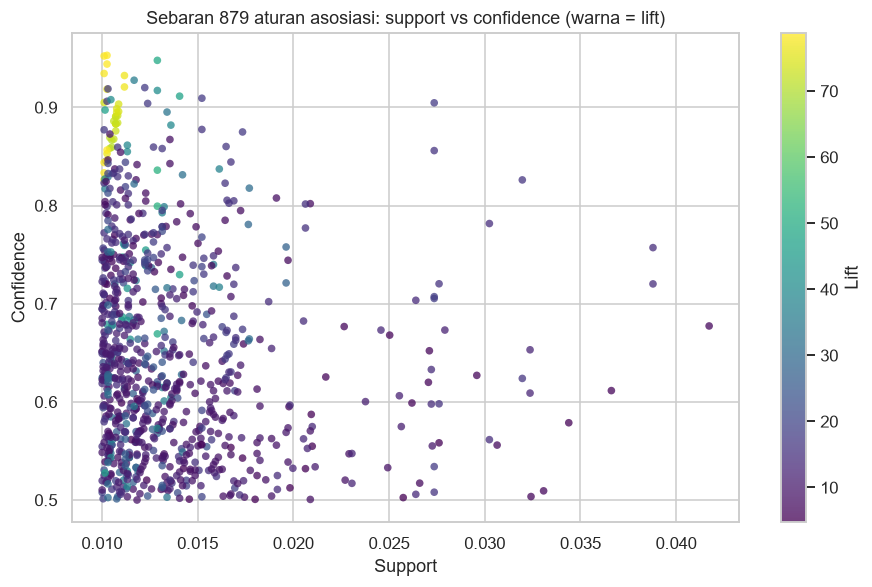

In [28]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sc = ax.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis",
                s=25, alpha=0.75, edgecolor="none")
cb = plt.colorbar(sc, ax=ax)
cb.set_label("Lift")
ax.set_xlabel("Support")
ax.set_ylabel("Confidence")
ax.set_title(f"Sebaran {len(rules)} aturan asosiasi: support vs confidence (warna = lift)")
plt.tight_layout()
plt.show()

### 5.1 Memilih tiga aturan terbaik berdasarkan lift
Jika diurutkan murni berdasarkan lift, daftar teratas **didominasi satu keluarga produk** (rangkaian *HERB MARKER*) dan memuat banyak aturan kembar (arah A→C dan C→A, atau permutasi itemset yang sama). Agar tiga aturan terpilih informatif dan tidak redundan, pemilihan dilakukan bertahap:
1. urutkan aturan menurut **lift** (tie-break: confidence);
2. untuk itemset yang sama, ambil satu aturan terbaik saja;
3. untuk setiap keluarga produk, ambil satu aturan terbaik. "Keluarga" didefinisikan sebagai kata pertama (≥ 4 huruf, bukan angka) yang dimiliki **bersama** oleh semua produk dalam aturan, misalnya `HERB` untuk seluruh *herb marker* atau `REGENCY` untuk rangkaian peralatan teh Regency;
4. ambil **tiga** teratas.

In [29]:
rules["itemset"] = rules.apply(lambda r: frozenset(r["antecedents"] | r["consequents"]), axis=1)

def keluarga_produk(itemset):
    # kata pertama (>= 4 huruf, bukan angka) yang dimiliki semua produk dalam itemset
    daftar = sorted(itemset)
    kata_umum = set.intersection(*[set(p.replace("'", "").split()) for p in daftar])
    for kata in daftar[0].replace("'", "").split():
        if kata in kata_umum and len(kata) >= 4 and not kata.isdigit():
            return kata
    return " | ".join(daftar)          # tidak ada kata bersama -> dianggap keluarga tersendiri

rules["keluarga"] = rules["itemset"].apply(keluarga_produk)

urut = rules.sort_values(["lift", "confidence"], ascending=False)
unik_itemset = urut.drop_duplicates("itemset")
best3 = unik_itemset.drop_duplicates("keluarga").head(3).reset_index(drop=True)

best3_tampil = best3[kolom + ["jumlah_invoice", "keluarga"]]
display(best3_tampil)
print("Kandidat berikutnya (peringkat 4-8):")
display(unik_itemset.drop_duplicates("keluarga").iloc[3:8][kolom + ["jumlah_invoice", "keluarga"]].reset_index(drop=True))

,antecedents_txt,consequents_txt,support,confidence,lift,jumlah_invoice,keluarga
0,HERB MARKER THYME,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,0.0103,0.8565,78.7738,203,HERB
1,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN + REGENCY TEA PLATE ROSES,0.0129,0.8361,51.8230,255,REGENCY
2,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.0111,0.7474,46.3296,219,WOODEN


Kandidat berikutnya (peringkat 4-8):


,antecedents_txt,consequents_txt,support,confidence,lift,jumlah_invoice,keluarga
0,POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,0.0113,0.7157,43.1422,224,POPPYS
1,JAM JAR WITH GREEN LID,JAM JAR WITH PINK LID,0.0115,0.7418,42.8895,227,WITH
2,CHILDRENS CUTLERY DOLLY GIRL,CHILDRENS CUTLERY SPACEBOY,0.0112,0.7595,41.7128,221,CHILDRENS
3,PINK POLKADOT CUP,BLUE POLKADOT CUP,0.0105,0.6775,41.2206,208,POLKADOT
4,SMALL CHOCOLATES PINK BOWL,SMALL MARSHMALLOWS PINK BOWL,0.0102,0.8171,36.1431,201,SMALL


In [30]:
leverage_conv = best3[["antecedents_txt", "consequents_txt", "leverage", "conviction"]]
display(leverage_conv)

,antecedents_txt,consequents_txt,leverage,conviction
0,HERB MARKER THYME,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,0.0101,6.8948
1,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN + REGENCY TEA PLATE ROSES,0.0126,6.0016
2,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.0108,3.8956


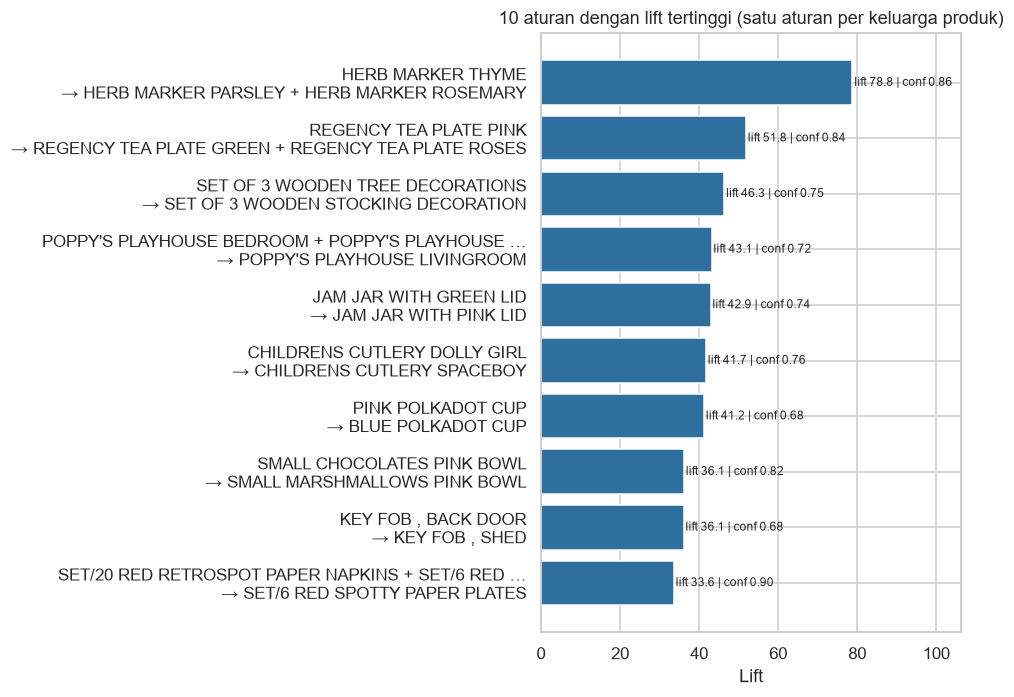

In [31]:
top = unik_itemset.drop_duplicates("keluarga").head(10).iloc[::-1]
import textwrap
potong = lambda t: textwrap.shorten(t, width=52, placeholder=" …")
etiket = [f"{potong(a)}\n→ {potong(c)}" for a, c in zip(top["antecedents_txt"], top["consequents_txt"])]

plt.figure(figsize=(9, 6.5))
plt.barh(etiket, top["lift"], color="#2E6F9E")
for i, (l, c) in enumerate(zip(top["lift"], top["confidence"])):
    plt.text(l + 0.5, i, f"lift {l:.1f} | conf {c:.2f}", va="center", fontsize=8)
plt.xlim(0, top["lift"].max() * 1.35)
plt.xlabel("Lift")
plt.title("10 aturan dengan lift tertinggi (satu aturan per keluarga produk)")
plt.tight_layout()
plt.show()

### 5.2 Interpretasi tiga aturan terbaik dalam konteks bisnis ritel
Tabel berikut menunjukkan bahwa *lift* merupakan rasio antara peluang bersyarat P(C|A) (= confidence) dan peluang dasar P(C). Contoh aturan 1: peluang dasar membeli *Herb Marker Parsley + Rosemary* hanya sekitar 1,09%, tetapi bila pelanggan sudah membeli *Herb Marker Thyme* peluangnya melonjak menjadi sekitar 85,7%, yaitu ±79 kali lebih besar.

In [32]:
detail = best3[["antecedents_txt", "consequents_txt", "antecedent support", "consequent support",
                "support", "confidence", "lift"]].copy()
detail.columns = ["antecedent", "consequent", "P(A)", "P(C)", "P(A,C)=support", "P(C|A)=confidence", "lift"]
detail["lift = P(C|A)/P(C)"] = detail["P(C|A)=confidence"] / detail["P(C)"]
display(detail)

,antecedent,consequent,P(A),P(C),"P(A,C)=support",P(C|A)=confidence,lift,lift = P(C|A)/P(C)
0,HERB MARKER THYME,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,0.0120,0.0109,0.0103,0.8565,78.7738,78.7738
1,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN + REGENCY TEA PLATE ROSES,0.0154,0.0161,0.0129,0.8361,51.8230,51.8230
2,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.0148,0.0161,0.0111,0.7474,46.3296,46.3296


**Aturan 1 — `HERB MARKER THYME` → `HERB MARKER PARSLEY + HERB MARKER ROSEMARY`** (support 0,0103 ≈ 203 invoice; confidence 0,857; lift 78,8)
- *Arti:* sekitar 1% dari seluruh transaksi memuat ketiga penanda herba tersebut sekaligus; dari transaksi yang memuat thyme, 85,7% juga memuat parsley dan rosemary. Hubungannya ±79 kali lebih kuat daripada jika produk-produk itu dibeli secara independen (lift ≫ 1).
- *Makna bisnis:* produk-produk ini tampaknya merupakan satu seri (penanda tanaman herba berbagai jenis) yang dibeli sebagai satu paket koleksi. Toko dapat menjual sebagai **bundling / paket lengkap herb marker** dan menampilkan seluruh varian berdampingan pada halaman produk atau rak yang sama.

**Aturan 2 — `REGENCY TEA PLATE PINK` → `REGENCY TEA PLATE GREEN + REGENCY TEA PLATE ROSES`** (support 0,0129 ≈ 255 invoice; confidence 0,836; lift 51,8)
- *Arti:* pembeli piring teh Regency warna pink umumnya (83,6%) juga membeli varian hijau dan *roses*, padahal peluang dasar membeli kedua varian itu hanya sekitar 1,6%.
- *Makna bisnis:* pelanggan (kemungkinan besar pedagang/grosir) melengkapi seluruh varian warna dari satu desain. Cocok untuk **cross-selling "lengkapi set warna"**, rekomendasi otomatis di keranjang belanja, dan perencanaan stok yang menjaga ketiga varian tersedia bersamaan; jika satu varian habis, penjualan varian lain ikut berisiko.

**Aturan 3 — `SET OF 3 WOODEN TREE DECORATIONS` → `SET OF 3 WOODEN STOCKING DECORATION`** (support 0,0111 ≈ 219 invoice; confidence 0,747; lift 46,3)
- *Arti:* tiga perempat pembeli dekorasi pohon kayu juga membeli dekorasi kaus kaki kayu, ±46 kali lebih sering dari kebetulan.
- *Makna bisnis:* keduanya adalah dekorasi Natal. Analisis tambahan di bawah menunjukkan sebagian besar invoice aturan ini terjadi pada **September–November**, sehingga pola ini bersifat musiman. Implikasinya: promosi paket dekorasi Natal dan penambahan stok perlu dimulai sebelum kuartal terakhir.

In [33]:
# Pola musiman: bulan terjadinya invoice yang memuat ketiga aturan terpilih
tgl_invoice = df.groupby("InvoiceNo")["InvoiceDate"].min()
nama_bulan = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
              7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}

for i, r in best3.iterrows():
    produk = list(r["itemset"])
    ada = basket[produk].all(axis=1)
    bulan = tgl_invoice.loc[ada[ada].index].dt.month
    sep_nov = bulan.between(9, 11).mean() * 100
    top4 = bulan.map(nama_bulan).value_counts().head(4).to_dict()
    print(f"Aturan {i + 1} ({r['keluarga']}): {len(bulan)} invoice, {sep_nov:.1f}% terjadi pada Sep-Nov; bulan terbanyak: {top4}")

pembanding = tgl_invoice.dt.month.between(9, 11).mean() * 100
print(f"Pembanding: {pembanding:.1f}% dari seluruh invoice terjadi pada Sep-Nov")

Aturan 1 (HERB): 203 invoice, 14.3% terjadi pada Sep-Nov; bulan terbanyak: {'Mei': 34, 'Jun': 28, 'Des': 24, 'Mar': 24}
Aturan 2 (REGENCY): 255 invoice, 36.1% terjadi pada Sep-Nov; bulan terbanyak: {'Mei': 68, 'Sep': 37, 'Jun': 32, 'Okt': 32}
Aturan 3 (WOODEN): 219 invoice, 82.6% terjadi pada Sep-Nov; bulan terbanyak: {'Nov': 89, 'Okt': 61, 'Sep': 31, 'Des': 22}
Pembanding: 33.2% dari seluruh invoice terjadi pada Sep-Nov


### 5.3 Aturan dengan support tinggi (pola yang paling sering terjadi)
Aturan dengan lift tertinggi berasal dari produk bersupport kecil (≈1%). Sebagai pelengkap, aturan dengan **support tertinggi** (tabel di atas) menunjukkan pola yang berdampak lebih luas pada penjualan:
- `JUMBO BAG PINK POLKADOT` → `JUMBO BAG RED RETROSPOT`: support 0,042 (±825 invoice), confidence 0,677, lift 6,4.
- `GREEN REGENCY TEACUP AND SAUCER` ↔ `ROSES REGENCY TEACUP AND SAUCER`: support 0,039 (±767 invoice), confidence 0,72–0,76, lift 14,1.

Lift-nya lebih rendah, tetapi cakupan transaksinya ±4× lebih besar sehingga sangat relevan untuk penataan produk dan promosi paket tas jumbo maupun cangkir-piring Regency.

In [34]:
hasil_akhir = rules.sort_values(["lift", "confidence"], ascending=False)[
    ["antecedents_txt", "consequents_txt", "antecedent support", "consequent support",
     "support", "confidence", "lift", "leverage", "conviction", "jumlah_invoice"]
].reset_index(drop=True)
hasil_akhir.to_csv("hasil_aturan_asosiasi.csv", index=False)
print(f"{len(hasil_akhir)} aturan disimpan ke hasil_aturan_asosiasi.csv")

879 aturan disimpan ke hasil_aturan_asosiasi.csv


## 6. Kesimpulan

**Hasil pengolahan data.** Dari 541.909 baris dan 25.900 invoice, pembersihan (Description kosong, invoice batal, Quantity ≤ 0, serta baris non-produk dan harga ≤ 0) menyisakan **527.759 baris, 19.773 transaksi, dan 3.994 produk unik**. Data keranjang berbentuk matriks one-hot yang sangat jarang (kepadatan ±0,66%), dengan median 15 produk unik per invoice dan 90,5% invoice berasal dari United Kingdom.

**Hasil algoritma.** Dengan *minimum support* 0,01 dan *minimum confidence* 0,5, Apriori menemukan **1.892 frequent itemset** (822 berisi satu produk, 819 dua produk, 228 tiga produk, 22 empat produk, 1 lima produk) dan **879 aturan asosiasi**. FP-Growth menghasilkan itemset dan nilai support yang identik. Seluruh aturan memiliki lift > 1 (minimum 4,7; median 12,3; maksimum 78,8) sehingga tidak ada aturan yang menunjukkan hubungan negatif.

**Pola yang ditemukan.**
1. **Pelengkap satu seri/varian produk** (herb marker, piring teh Regency, cangkir Regency, boneka Poppy's Playhouse, jam jar, peralatan makan anak). Pelanggan yang membeli satu varian sangat mungkin membeli varian lainnya.
2. **Pola musiman**, terutama dekorasi Natal kayu yang terkonsentrasi pada September–November.
3. **Produk terlaris dalam satu keluarga yang sama** (tas jumbo dan lunch bag), berdampak pada banyak transaksi (support 3–4%) walau lift-nya moderat.

**Rekomendasi bisnis:** bundling "set lengkap" untuk produk satu seri, rekomendasi cross-selling pada keranjang belanja, penataan produk bervarian berdekatan, serta penyiapan stok dan promosi dekorasi Natal sebelum kuartal terakhir.

**Keterbatasan.** (1) Aturan terkuat umumnya berupa hubungan antarvarian dalam satu seri produk, sehingga sebagian bersifat "sudah wajar"; hubungan lintas kategori yang lebih mengejutkan baru muncul bila support diturunkan atau produk dikelompokkan ke kategori. (2) Lift mudah membesar pada produk bersupport kecil sehingga perlu dibaca bersama support dan jumlah invoice. (3) Pelanggan dataset ini sebagian besar pedagang grosir di Inggris (keranjang besar), sehingga pola belum tentu berlaku untuk pembeli eceran atau negara lain. (4) Association rule menunjukkan keterkaitan, **bukan hubungan sebab-akibat**. (5) Analisis memakai `Description` sebagai item; varian penulisan nama yang berbeda sudah dinormalisasi, tetapi satu produk dengan beberapa `StockCode` tetap dihitung berdasarkan nama.